# Averaged State-Space Model of the Interleaved Half-Bridge Shuffler
### Derivation · Stability · Controllability · Discretisation · Cascaded PI Design

This notebook is the **dynamics companion** to `shuffler_sim.ipynb`. Where that notebook treated each
shuffler as an ideal current-redistribution element, here we open the box and model the **internal
power-electronic dynamics** of one interleaved half-bridge serial partial-power converter (S-PPC).

It reproduces and extends Appendix B of the progress report *Adaptive Control of Solar Power Shufflers*
(equation tags `(B.x)` are cross-referenced throughout):

1. per-switch-state circuit equations $\rightarrow$ time-averaged bilinear model;
2. equilibrium operating point and small-signal **linearisation**;
3. **eigenvalues / stability**, modal (common/differential) decomposition;
4. **controllability & observability** (why per-phase current sensing is mandatory);
5. **discretisation** (ZOH) at the switching frequency;
6. a coupled-inductor refinement (ERUC23-421K T-model) and its effect on the poles;
7. **visuals**: $s$- and $z$-plane pole maps, **phase portraits**, **root loci**, Bode plots, step responses;
8. analytical **cascaded PI** gain design for the three control loops.

The treatment is deliberately math-heavy and uses `sympy` for the symbolic derivations and
`python-control` for the frequency-domain work. Switching ripple and dead-time are **out of scope** here
(they belong to the QSPICE / PLECS switching models); this is the averaged, control-design model.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import scipy.linalg as sla
import control as ct

sp.init_printing(use_unicode=True)

# ---------------------------------------------------------------------------
# Component values  (interleaved half-bridge shuffler, ERUC23-421K inductor)
# ---------------------------------------------------------------------------
L_IND   = 8.2e-6      # H   single-inductor approximation used in the report
L_SELF  = 7.9e-6      # H   coupled-inductor self  = L_branch(2.05u) + L_m(5.85u)
L_M     = 5.85e-6     # H   coupled-inductor mutual = magnetising inductance
R_W     = 1.85e-3     # ohm winding resistance per branch
C_CAP   = 100e-6      # F   substring decoupling capacitor (C1 = C2)
F_SW    = 200e3       # Hz  switching frequency
T_S     = 1/F_SW      # s   sample period (5 us)

# ---------------------------------------------------------------------------
# Nominal operating point (symmetric, D = 0.5)
# ---------------------------------------------------------------------------
D_OP    = 0.5
VC1_OP  = 38.0        # V   top substring voltage  (~ module MPP voltage)
VC2_OP  = 38.0        # V   bottom substring voltage
VSIG    = VC1_OP + VC2_OP          # V   bus sum that sets actuator gain
IBAR    = 6.0         # A   per-phase steady inductor current
IPV1_OP, IPV2_OP = 6.0, 6.0
ILOAD_OP = 18.0

print(f'omega0 (D=0.5) = 1/sqrt(L*C) = {1/np.sqrt(L_IND*C_CAP):.0f} rad/s '
      f'= {1/np.sqrt(L_IND*C_CAP)/(2*np.pi)/1e3:.2f} kHz')
print(f'characteristic impedance Z0 = sqrt(L/C) = {np.sqrt(L_IND/C_CAP):.3f} ohm')
print(f'sample period T_s = {T_S*1e6:.1f} us')

omega0 (D=0.5) = 1/sqrt(L*C) = 34922 rad/s = 5.56 kHz
characteristic impedance Z0 = sqrt(L/C) = 0.286 ohm
sample period T_s = 5.0 us


## 1 · Topology, state variables and sign conventions

The S-PPC is an **interleaved half-bridge buck-boost** across two series PV substrings. The substrings
$PV_1$ (top, $V_{top}\!\to\!V_{mid}$) and $PV_2$ (bottom, $V_{mid}\!\to\!\mathrm{GND}$) are decoupled by
capacitors $C_1,\,C_2$. Two half-bridge legs (Phase A, Phase B) each drive one winding of a coupled
inductor from their switch node; the two phases are run **180° interleaved** (carrier phase-shifted) so
their ripple currents partially cancel.

State, control and exogenous vectors (B.1)–(B.3):

$$x=\begin{bmatrix}I_{L1}&I_{L2}&V_{C1}&V_{C2}\end{bmatrix}^{\!\top},\quad
u_d=\begin{bmatrix}d_A&d_B\end{bmatrix}^{\!\top},\quad
u_e=\begin{bmatrix}I_{pv1}&I_{pv2}&I_{load}\end{bmatrix}^{\!\top}$$

**Sign conventions.** $I_{Lk}>0$ flows $V_{mid}\!\to\!L_k\!\to\!\mathrm{SW}_k$; $V_{C1}=V_{top}-V_{mid}$;
$V_{C2}=V_{mid}$; $d_A,d_B$ are the per-phase **high-side** duty cycles. The two phase currents
$I_{L1},I_{L2}$ are the inner-loop controlled variables.

## 2 · Valid switching states

Four switches give $2^4=16$ combinations; the 7 that short a leg ($S_1S_2$ or $S_3S_4$) are forbidden,
leaving **9 valid states**. Only the **four dual-switch states** are control-relevant — the single-switch
and all-off states occur only during dead-time and freewheel (via body diodes) into one of the four. We
therefore model dead-time later, in the switching simulator, and build the averaged model on these four:

| State | Switches ON | Phase A | Phase B | $V_{L1}$ | $V_{L2}$ |
|-------|-------------|---------|---------|----------|----------|
| 9 | $S_1+S_3$ | high | high | $-V_{C1}$ | $-V_{C1}$ |
| 8 | $S_1+S_4$ | high | low  | $-V_{C1}$ | $+V_{C2}$ |
| 7 | $S_2+S_3$ | low  | high | $+V_{C2}$ | $-V_{C1}$ |
| 6 | $S_2+S_4$ | low  | low  | $+V_{C2}$ | $+V_{C2}$ |

Each state is $\dot x = A_i x + B u_e$ with a **common** $B$ (the exogenous currents enter the capacitor
nodes independently of switch position). Below we build each $A_i$ directly from KCL/KVL (B.3).

In [2]:
# Symbols: state x = [I_L1, I_L2, V_C1, V_C2]; duties d_A,d_B; exogenous I_pv1,I_pv2,I_load
IL1, IL2, VC1, VC2 = sp.symbols('I_L1 I_L2 V_C1 V_C2', real=True)
dA, dB             = sp.symbols('d_A d_B', real=True)
Ipv1, Ipv2, Iload  = sp.symbols('I_pv1 I_pv2 I_load', real=True)
L, M, Rw, C1, C2   = sp.symbols('L M R C1 C2', positive=True)
x   = sp.Matrix([IL1, IL2, VC1, VC2])
u_d = sp.Matrix([dA, dB])
u_e = sp.Matrix([Ipv1, Ipv2, Iload])

# Per-state inductor port voltages and capacitor currents (Appendix B.3).
#   high-side ON  -> V_Lk = -V_C1 ,  phase current charges C1
#   low-side  ON  -> V_Lk = +V_C2 ,  phase current discharges C2
def state_matrix(sA, sB):
    """A_i for a dual-switch state; sA,sB in {1:high-side ON, 0:low-side ON}."""
    vL1 = (-VC1 if sA else VC2)
    vL2 = (-VC1 if sB else VC2)
    dIL1 = vL1 / L
    dIL2 = vL2 / L
    dVC1 = ((IL1 if sA else 0) + (IL2 if sB else 0)) / C1     # high-side phases charge C1
    dVC2 = (-(IL1 if not sA else 0) - (IL2 if not sB else 0)) / C2  # low-side phases discharge C2
    f_state = sp.Matrix([dIL1, dIL2, dVC1, dVC2])
    return f_state.jacobian(x)

A9 = state_matrix(1, 1)   # S1+S3  both high-side
A8 = state_matrix(1, 0)   # S1+S4  diagonal (A high, B low)
A7 = state_matrix(0, 1)   # S2+S3  diagonal (A low, B high)
A6 = state_matrix(0, 0)   # S2+S4  both low-side

print('State 9 (both high-side)  A9 =')
sp.pprint(A9)
print('\nState 6 (both low-side)   A6 =')
sp.pprint(A6)
print('\nStates 7 / 8 are the diagonal configurations (one phase high, one low).')

State 9 (both high-side)  A9 =
⎡        -1    ⎤
⎢0   0   ───  0⎥
⎢         L    ⎥
⎢              ⎥
⎢        -1    ⎥
⎢0   0   ───  0⎥
⎢         L    ⎥
⎢              ⎥
⎢1   1         ⎥
⎢──  ──   0   0⎥
⎢C₁  C₁        ⎥
⎢              ⎥
⎣0   0    0   0⎦

State 6 (both low-side)   A6 =
⎡             1⎤
⎢ 0    0   0  ─⎥
⎢             L⎥
⎢              ⎥
⎢             1⎥
⎢ 0    0   0  ─⎥
⎢             L⎥
⎢              ⎥
⎢ 0    0   0  0⎥
⎢              ⎥
⎢-1   -1       ⎥
⎢───  ───  0  0⎥
⎣C₂   C₂       ⎦

States 7 / 8 are the diagonal configurations (one phase high, one low).


## 3 · Time-averaged bilinear model

Assuming continuous conduction and independent phase switching, the dwell fractions of states
$\{9,8,7,6\}$ over one period are $d_Ad_B,\;d_A(1{-}d_B),\;(1{-}d_A)d_B,\;(1{-}d_A)(1{-}d_B)$, summing to 1.
The averaged state matrix is the dwell-weighted sum (B.5):

$$\bar A = d_Ad_B\,A_9 + d_A(1{-}d_B)\,A_8 + (1{-}d_A)d_B\,A_7 + (1{-}d_A)(1{-}d_B)\,A_6$$

Carrying out the sum gives the **averaged nonlinear model**. Each inductor sees the duty-weighted average
of $-V_{C1}$ (high-side) and $+V_{C2}$ (low-side); $C_1$ is charged by every phase whose high-side is on,
$C_2$ discharged by every phase whose low-side is on. We write it directly with a general inductance
matrix and winding resistance so the coupled-inductor case (§6) is a parameter change.

In [3]:
# Dwell-weighted average of the four dual-switch state matrices (Appendix B.4):
Abar = (dA*dB*A9 + dA*(1-dB)*A8 + (1-dA)*dB*A7 + (1-dA)*(1-dB)*A6)
Abar = sp.simplify(Abar)

# Exogenous input matrix B (identical across states): PV/load currents enter the caps.
#   C1 receives I_pv1 and loses I_load ; C2 receives I_pv2
Bexo = sp.Matrix([[0, 0, 0],
                  [0, 0, 0],
                  [1/C1, 0, -1/C1],
                  [0, 1/C2, 0]])

# Full averaged NONLINEAR model, written with a general inductance matrix
#   Lmat = [[L, M],[M, L]] and winding resistance Rw (M=0, Rw=0 -> report model).
Lmat = sp.Matrix([[L, M], [M, L]])
vL = sp.Matrix([-dA*VC1 + (1-dA)*VC2,
                -dB*VC1 + (1-dB)*VC2])
dI = Lmat.inv() * (vL - Rw*sp.Matrix([IL1, IL2]))
dVC1 = (dA*IL1 + dB*IL2 + Ipv1 - Iload) / C1
dVC2 = (Ipv2 - (1-dA)*IL1 - (1-dB)*IL2) / C2
f_avg = sp.Matrix([dI[0], dI[1], dVC1, dVC2])

print('Averaged nonlinear model  dx/dt = f(x, d, u_e):')
sp.pprint(f_avg)

# cross-check: with M=0, Rw=0 the state-Jacobian equals the dwell-weighted Abar
check = sp.simplify(f_avg.subs({M: 0, Rw: 0}).jacobian(x) - Abar)
print('\nJacobian(f)|_{M=0,R=0}  -  dwell-weighted Abar  =  zero matrix?',
      check == sp.zeros(4, 4))

Averaged nonlinear model  dx/dt = f(x, d, u_e):
⎡L⋅(-I_L1⋅R - V_C1⋅d_A + V_C2⋅(1 - d_A))   M⋅(-I_L2⋅R - V_C1⋅d_B + V_C2⋅(1 - d ↪
⎢─────────────────────────────────────── - ─────────────────────────────────── ↪
⎢                 2    2                                    2    2             ↪
⎢                L  - M                                    L  - M              ↪
⎢                                                                              ↪
⎢L⋅(-I_L2⋅R - V_C1⋅d_B + V_C2⋅(1 - d_B))   M⋅(-I_L1⋅R - V_C1⋅d_A + V_C2⋅(1 - d ↪
⎢─────────────────────────────────────── - ─────────────────────────────────── ↪
⎢                 2    2                                    2    2             ↪
⎢                L  - M                                    L  - M              ↪
⎢                                                                              ↪
⎢                       I_L1⋅d_A + I_L2⋅d_B - I_load + Iₚᵥ₁                    ↪
⎢                       ───────────────────────────────────  

## 4 · Equilibrium operating point

Setting $\dot x=0$. The two inductor (volt-second) balances force the duties equal and fix the capacitor
voltage ratio (B.6)–(B.7):

$$D_A=D_B\equiv D,\qquad \frac{\bar V_{C2}}{\bar V_{C1}}=\frac{D}{1-D}$$

So the **duty sets the voltage split** between the substrings — the steady-state lever the MPPT/voltage
loop will use. The differential duty $d_A-d_B$ is a *transient-only* input (it cannot persist at
equilibrium). Adding the load current to the charge balance gives the steady duty and per-phase current
(B.8)–(B.9):

$$D=\frac{I_{load}-I_{pv1}}{I_{load}-I_{pv1}+I_{pv2}},\qquad \bar I=\frac{I_{pv2}}{2(1-D)}$$

In [4]:
# Equilibrium: set derivatives to zero with d_A=d_B=D and I_L1=I_L2=Ibar.
D, Ibar_s = sp.symbols('D Ibar', positive=True)
sub_eq = {dA: D, dB: D, IL1: Ibar_s, IL2: Ibar_s, M: 0, Rw: 0}
feq = f_avg.subs(sub_eq)

# (B.7) volt-second balance -> capacitor voltage ratio
VC2_sol = sp.solve(sp.Eq(feq[0], 0), VC2)[0]
print('Volt-second balance  =>  V_C2 =', VC2_sol, '   i.e.  V_C2/V_C1 = D/(1-D)   (B.7)')

# (B.8),(B.9) charge balance with the load -> steady duty and per-phase current
sol = sp.solve([sp.Eq(feq[2], 0), sp.Eq(feq[3], 0)], [D, Ibar_s], dict=True)[0]
D_star    = sp.simplify(sol[D])
Ibar_star = sp.simplify(sol[Ibar_s])
print('\nSteady-state duty (B.8):   D     =', D_star)
print('Per-phase current (B.9):   Ibar  =', Ibar_star,
      '   ( = I_pv2 / [2(1-D)] )')

# numeric check at the nominal operating point
num = {Ipv1: IPV1_OP, Ipv2: IPV2_OP, Iload: ILOAD_OP}
print('\nAt I_pv1=%.0f, I_pv2=%.0f, I_load=%.0f A :  D = %.3f ,  Ibar = %.2f A'
      % (IPV1_OP, IPV2_OP, ILOAD_OP, float(D_star.subs(num)), float(Ibar_star.subs(num))))

Volt-second balance  =>  V_C2 = -D*V_C1/(D - 1)    i.e.  V_C2/V_C1 = D/(1-D)   (B.7)

Steady-state duty (B.8):   D     = (I_load - I_pv1)/(I_load - I_pv1 + I_pv2)
Per-phase current (B.9):   Ibar  = I_load/2 - I_pv1/2 + I_pv2/2    ( = I_pv2 / [2(1-D)] )

At I_pv1=6, I_pv2=6, I_load=18 A :  D = 0.667 ,  Ibar = 9.00 A


## 5 · Small-signal linearisation

Perturb $x=\bar X+\tilde x$, $d=D+\tilde d$, $u_e=\bar U_e+\tilde u_e$ and keep first-order terms (B.6):

$$\dot{\tilde x}=\tilde A\,\tilde x+\tilde B_d\,\tilde d+\tilde B_e\,\tilde u_e$$

$\tilde A$ depends on $D$ and $L,C$; $\tilde B_d$ additionally on the bus sum $V_\Sigma=\bar V_{C1}+\bar
V_{C2}$ and the steady per-phase current $\bar I$ (the **actuator effectiveness** scales with bus voltage
and current); $\tilde B_e$ is duty-independent. Note the structural degeneracy: rows 1,2 of $\tilde A$ are
identical and so are columns 1,2 — each deficiency yields one zero eigenvalue, which the modal split in §8
makes explicit.

In [5]:
# Linearise the averaged model about the operating point: Jacobians give the
# small-signal matrices  dx~/dt = A~ x~ + B~_d d~ + B~_e u_e~   (Figure 2 / B.6).
A_tld  = f_avg.jacobian(x)
Bd_tld = f_avg.jacobian(u_d)
Be_tld = f_avg.jacobian(u_e)

# Evaluate symbolically at the symmetric operating point (d_A=d_B=D, I_L=Ibar,
# V_C2/V_C1 = D/(1-D)) with the report's independent-inductor model (M=0).
op = {dA: sp.Symbol('D'), dB: sp.Symbol('D'),
      IL1: sp.Symbol('Ibar'), IL2: sp.Symbol('Ibar'), M: 0, Rw: 0}
Ds, Is = sp.Symbol('D'), sp.Symbol('Ibar')
VSig_s = sp.Symbol('V_Sigma')

A_op  = sp.simplify(A_tld.subs(op))
Bd_op = sp.simplify(Bd_tld.subs(op))

print('A~  (operating-point state matrix):')
sp.pprint(A_op)
print('\nB~_d  (duty-perturbation input matrix):')
sp.pprint(Bd_op)
print('\nB~_e  (exogenous input matrix, duty-independent):')
sp.pprint(sp.simplify(Be_tld.subs(op)))
print('\nNote: rows 1,2 of A~ are identical and cols 1,2 are identical ->')
print('each rank deficiency contributes one zero eigenvalue (modal split next).')

A~  (operating-point state matrix):
⎡              -D   1 - D⎤
⎢  0      0    ───  ─────⎥
⎢               L     L  ⎥
⎢                        ⎥
⎢              -D   1 - D⎥
⎢  0      0    ───  ─────⎥
⎢               L     L  ⎥
⎢                        ⎥
⎢ D      D               ⎥
⎢ ──     ──     0     0  ⎥
⎢ C₁     C₁              ⎥
⎢                        ⎥
⎢D - 1  D - 1            ⎥
⎢─────  ─────   0     0  ⎥
⎣ C₂     C₂              ⎦

B~_d  (duty-perturbation input matrix):
⎡-V_C1 - V_C2              ⎤
⎢────────────       0      ⎥
⎢     L                    ⎥
⎢                          ⎥
⎢              -V_C1 - V_C2⎥
⎢     0        ────────────⎥
⎢                   L      ⎥
⎢                          ⎥
⎢     I̅             I̅      ⎥
⎢     ──            ──     ⎥
⎢     C₁            C₁     ⎥
⎢                          ⎥
⎢     I̅             I̅      ⎥
⎢     ──            ──     ⎥
⎣     C₂            C₂     ⎦

B~_e  (exogenous input matrix, duty-independent):
⎡0   0    0 ⎤
⎢           ⎥


## 6 · Coupled-inductor refinement (ERUC23-421K)

The report's first pass used **two independent inductors** ($L=8.2\,\mu$H). The real part (ERUC23-421K) is
a **coupled** inductor whose datasheet T-model is: per branch a winding resistance $R$ and a leakage
$L_{branch}$, plus a shared magnetising inductance $L_m$ across a 1:1 ideal transformer. Referenced to a
common dotted node this is the inductance matrix

$$\mathbf L=\begin{bmatrix}L_{self}&M\\ M&L_{self}\end{bmatrix},\quad L_{self}=L_{branch}+L_m,\;\;M=L_m,
\qquad \mathbf L\,\dot{\mathbf I}= \mathbf v_L - R\,\mathbf I$$

with modal inductances $L_{cm}=L_{self}+M$ (common/DC) and $L_{dm}=L_{self}-M=L_{branch}$
(differential/ripple). The schematic below is exactly the datasheet representation; setting $M=0,\,R=0$
recovers the two-inductor model, so we can carry **both** and compare. (For back-of-envelope control design
the single-$L$ model is adequate — the coupled model matters mainly for the damping it adds and is where
QSPICE/Simulink will take over.)

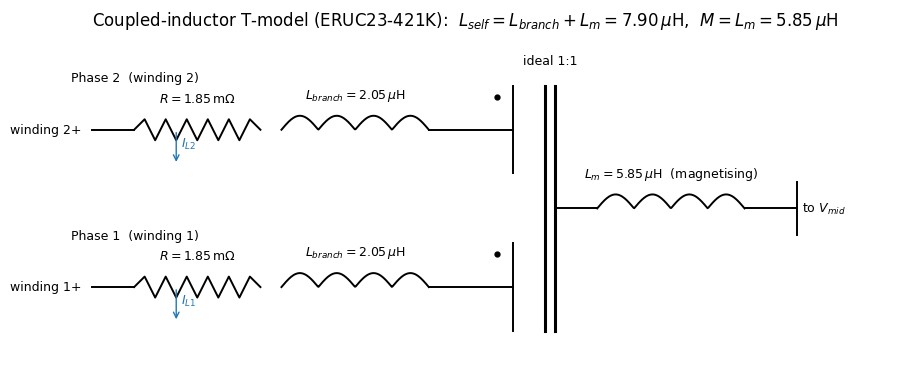

In [6]:
# Schematic of the coupled-inductor model used for the branch inductances
# (ERUC23-421K datasheet T-model): per branch a winding resistance R and a
# leakage inductance L_branch, then a 1:1 ideal transformer with a shared
# magnetising inductance L_m. This is the "represent the inductors differently"
# refinement; setting M = L_m = 0 recovers the two-independent-inductor model.
from matplotlib.patches import FancyArrowPatch

def resistor(ax, x0, x1, y, label):
    n = 6; xs = np.linspace(x0, x1, 2*n+1); ys = np.full_like(xs, y)
    ys[1:-1:2] = y + 0.12; ys[2:-1:2] = y - 0.12
    ax.plot(xs, ys, 'k', lw=1.4)
    ax.text((x0+x1)/2, y+0.32, label, ha='center', fontsize=9)

def coil(ax, x0, x1, y, label, n=4):
    xs = np.linspace(x0, x1, 200)
    ax.plot(xs, y + 0.16*np.abs(np.sin(np.pi*n*(xs-x0)/(x1-x0))), 'k', lw=1.4)
    ax.text((x0+x1)/2, y+0.36, label, ha='center', fontsize=9)

fig, ax = plt.subplots(figsize=(11, 4.2))
for yb, ph, wd in ((2.4, 'Phase 2  (winding 2)', '2'), (0.6, 'Phase 1  (winding 1)', '1')):
    ax.plot([0.2, 0.6], [yb, yb], 'k', lw=1.4)
    resistor(ax, 0.6, 1.8, yb, f'$R={R_W*1e3:.2f}\\,$m$\\Omega$')
    coil(ax, 2.0, 3.4, yb, f'$L_{{branch}}={(L_SELF-L_M)*1e6:.2f}\\,\\mu$H')
    ax.plot([3.4, 4.2], [yb, yb], 'k', lw=1.4)
    ax.plot([4.2, 4.2], [yb-0.5, yb+0.5], 'k', lw=1.4)            # transformer winding bar
    ax.plot(4.05, yb+0.38, 'k.', ms=7)                           # polarity dot
    ax.text(0.1, yb, ph.split('  ')[1][1:-1] + '+', ha='right', va='center', fontsize=9)
    ax.text(0.0, yb+0.55, ph, ha='left', fontsize=9)
# ideal transformer core + shared magnetising inductance
ax.plot([4.5, 4.5], [0.1, 2.9], 'k', lw=2.2)
ax.plot([4.6, 4.6], [0.1, 2.9], 'k', lw=2.2)
ax.text(4.55, 3.15, 'ideal 1:1', ha='center', fontsize=9)
coil(ax, 5.0, 6.4, 1.5, f'$L_m={L_M*1e6:.2f}\\,\\mu$H  (magnetising)')
ax.plot([4.6, 5.0], [1.5, 1.5], 'k', lw=1.4)
ax.plot([6.4, 6.9], [1.5, 1.5], 'k', lw=1.4)
ax.plot([6.9, 6.9], [1.2, 1.8], 'k', lw=1.4)
ax.text(6.95, 1.5, 'to $V_{mid}$', ha='left', va='center', fontsize=9)
ax.annotate('', xy=(1.0, 2.0), xytext=(1.0, 2.4),
            arrowprops=dict(arrowstyle='->', color='tab:blue'))
ax.text(1.05, 2.2, '$I_{L2}$', color='tab:blue', fontsize=9)
ax.annotate('', xy=(1.0, 0.2), xytext=(1.0, 0.6),
            arrowprops=dict(arrowstyle='->', color='tab:blue'))
ax.text(1.05, 0.4, '$I_{L1}$', color='tab:blue', fontsize=9)
ax.set_xlim(-0.3, 7.8); ax.set_ylim(-0.2, 3.5); ax.axis('off')
ax.set_title('Coupled-inductor T-model (ERUC23-421K):  '
             '$L_{self}=L_{branch}+L_m=%.2f\\,\\mu$H,  $M=L_m=%.2f\\,\\mu$H' %
             (L_SELF*1e6, L_M*1e6))
plt.show()

In [7]:
# ---------------------------------------------------------------------------
# Coupled-inductor (ERUC23-421K) refinement.
# Datasheet T-model: each branch has leakage L_branch and winding R; a shared
# magnetising inductance L_m sits next to the ideal 1:1 transformer. With both
# windings referenced to the same dotted node this gives the inductance matrix
#     Lmat = [[L_self, M],[M, L_self]],  L_self = L_branch + L_m,  M = L_m.
# Modal inductances:  common-mode (sum)  L_cm = L_self + M
#                     differential (ripple) L_dm = L_self - M  (= L_branch)
# ---------------------------------------------------------------------------
L_branch = L_SELF - L_M
print(f'L_self = L_branch + L_m = {L_branch*1e6:.2f} + {L_M*1e6:.2f} = {L_SELF*1e6:.2f} uH')
print(f'common-mode inductance  L_cm = L_self + M = {(L_SELF+L_M)*1e6:.2f} uH')
print(f'differential inductance L_dm = L_self - M = {(L_SELF-L_M)*1e6:.2f} uH  (= leakage)')
print(f'(the report used a single L = {L_IND*1e6:.1f} uH, close to L_self = {L_SELF*1e6:.1f} uH)')

# Numeric small-signal matrices at the operating point, either model.
_opbase = {dA: D_OP, dB: D_OP, IL1: IBAR, IL2: IBAR, VC1: VC1_OP, VC2: VC2_OP,
           C1: C_CAP, C2: C_CAP}

def num_model(coupled=False):
    """Return (A, Bd, Be) numeric small-signal matrices.
    coupled=False -> independent inductors L=L_IND, R=0  (report model)
    coupled=True  -> ERUC23-421K T-model + winding resistance."""
    sub = dict(_opbase)
    if coupled:
        sub.update({L: L_SELF, M: L_M, Rw: R_W})
    else:
        sub.update({L: L_IND, M: 0.0, Rw: 0.0})
    A  = np.array(A_tld.subs(sub)).astype(float)
    Bd = np.array(Bd_tld.subs(sub)).astype(float)
    Be = np.array(Be_tld.subs(sub)).astype(float)
    return A, Bd, Be

A_indep, Bd_indep, Be_indep = num_model(coupled=False)
A_coup,  Bd_coup,  Be_coup  = num_model(coupled=True)
print('\nIndependent-inductor A~ =')
print(np.array_str(A_indep, precision=1, suppress_small=True))

L_self = L_branch + L_m = 2.05 + 5.85 = 7.90 uH
common-mode inductance  L_cm = L_self + M = 13.75 uH
differential inductance L_dm = L_self - M = 2.05 uH  (= leakage)
(the report used a single L = 8.2 uH, close to L_self = 7.9 uH)

Independent-inductor A~ =
[[     0.       0.  -60975.6  60975.6]
 [     0.       0.  -60975.6  60975.6]
 [  5000.    5000.       0.       0. ]
 [ -5000.   -5000.       0.       0. ]]


## 7 · Open-loop eigenvalues and stability

With independent inductors the linearised plant is **marginally stable**: two integrators at the origin
and one undamped imaginary pair (B.10),

$$\sigma(\tilde A)=\{0,\,0,\,+j\omega_0,\,-j\omega_0\},\qquad
\omega_0^2=\frac{2D^2}{LC_1}+\frac{2(1-D)^2}{LC_2}$$

At $D=0.5,\,C_1=C_2$ this is simply $\omega_0=1/\sqrt{LC}$. Adding the winding resistance and coupling pulls
the resonant pair off the $j\omega$ axis into the left half-plane — the physical (but very light) damping.

Independent inductors (report model):
  eigenvalues: [-0.+34921.5j -0.-34921.5j  0.    +0.j   0.    +0.j ]
  => sigma(A) = {0, 0, +/- j*omega0},  omega0 = 34922 rad/s (5.56 kHz)
  marginally stable: an undamped LC resonance + two integrators.

Coupled inductor + winding R:
  eigenvalues: [ -67.3+26967.9j  -67.3-26967.9j -902.4    +0.j    -0.     +0.j ]
  resonant pair real part = -67.3 /s  ->  now a (lightly) damped focus.


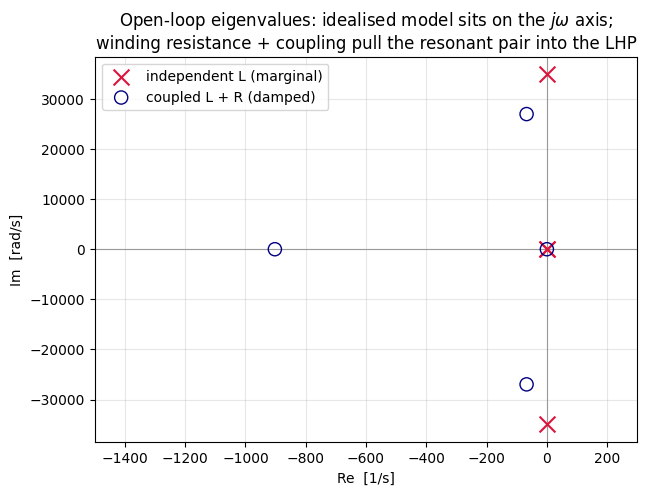

In [8]:
# Open-loop eigenvalues / stability (Appendix B.7, B.10).
ev_indep = np.linalg.eigvals(A_indep)
ev_coup  = np.linalg.eigvals(A_coup)
w0 = np.sqrt(2*D_OP**2/(L_IND*C_CAP) + 2*(1-D_OP)**2/(L_IND*C_CAP))

print('Independent inductors (report model):')
print('  eigenvalues:', np.array_str(ev_indep, precision=1, suppress_small=True))
print('  => sigma(A) = {0, 0, +/- j*omega0},  omega0 = %.0f rad/s (%.2f kHz)'
      % (w0, w0/(2*np.pi)/1e3))
print('  marginally stable: an undamped LC resonance + two integrators.\n')
print('Coupled inductor + winding R:')
print('  eigenvalues:', np.array_str(ev_coup, precision=1, suppress_small=True))
print('  resonant pair real part = %.1f /s  ->  now a (lightly) damped focus.'
      % ev_coup[np.argmax(np.abs(ev_coup.imag))].real)

# ---- s-plane pole map ----
fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(0, color='0.6', lw=0.8); ax.axvline(0, color='0.6', lw=0.8)
ax.scatter(ev_indep.real, ev_indep.imag, s=130, marker='x', color='crimson',
           label='independent L (marginal)', zorder=3)
ax.scatter(ev_coup.real, ev_coup.imag, s=90, marker='o', facecolors='none',
           edgecolors='navy', label='coupled L + R (damped)', zorder=3)
ax.set_xlabel('Re  [1/s]'); ax.set_ylabel('Im  [rad/s]')
ax.set_title('Open-loop eigenvalues: idealised model sits on the $j\\omega$ axis;\n'
             'winding resistance + coupling pull the resonant pair into the LHP')
ax.legend(); ax.grid(alpha=0.3)
ax.set_xlim(-1500, 300)
plt.show()

## 8 · Modal decomposition: common vs differential mode

Transform to $I_\Sigma=I_{L1}+I_{L2}$ and $I_\Delta=I_{L1}-I_{L2}$. The dynamics block-decouple:

* **differential mode** $I_\Delta$ — a pure integrator $L\,\dot{\tilde I}_\Delta=-V_\Sigma\,\tilde u_\delta$,
  driven only by the differential duty $\tilde u_\delta=\tilde d_A-\tilde d_B$;
* **common mode** $(I_\Sigma,V_{C1},V_{C2})$ — carries the resonance, $\lambda(\lambda^2+\omega_0^2)=0$.

This is the structural backbone of the whole control design: the **common-mode** duty $(d_A+d_B)/2$ moves
power between the substrings (voltage / MPPT), while the **differential** duty $d_A-d_B$ balances the two
phase currents — orthogonal actions on orthogonal modes.

In [9]:
# Modal decomposition into common-mode (sum) and differential-mode (difference)
# of the phase currents (Appendix B.7).  z = [I_sum, I_diff, V_C1, V_C2].
T    = np.array([[1, 1, 0, 0], [1, -1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]], float)
Tinv = np.linalg.inv(T)
Az   = T @ A_indep @ Tinv
Bdz  = T @ Bd_indep

print('A~ in modal coordinates (rows/cols: I_sum, I_diff, V_C1, V_C2):')
print(np.array_str(Az, precision=1, suppress_small=True))
print('\nThe I_diff row/column decouples -> a pure integrator (eigenvalue 0).')
print('The common-mode block (I_sum, V_C1, V_C2) carries the resonance:\n')

idx = [0, 2, 3]
Ac  = Az[np.ix_(idx, idx)]
print('common-mode A_c =')
print(np.array_str(Ac, precision=1, suppress_small=True))
lam = np.linalg.eigvals(Ac)
print('common-mode eigenvalues:', np.array_str(lam, precision=1, suppress_small=True))
print('characteristic poly:  lambda * (lambda^2 + omega0^2) = 0')
print('  -> {0, +/- j*omega0};  with the differential integrator => {0,0,+/-j*omega0}')
print('\nResonance vs duty:  omega0^2 = 2D^2/(L C1) + 2(1-D)^2/(L C2)')

A~ in modal coordinates (rows/cols: I_sum, I_diff, V_C1, V_C2):
[[      0.        0.  -121951.2  121951.2]
 [      0.        0.        0.        0. ]
 [   5000.        0.        0.        0. ]
 [  -5000.        0.        0.        0. ]]

The I_diff row/column decouples -> a pure integrator (eigenvalue 0).
The common-mode block (I_sum, V_C1, V_C2) carries the resonance:

common-mode A_c =
[[      0.  -121951.2  121951.2]
 [   5000.        0.        0. ]
 [  -5000.        0.        0. ]]
common-mode eigenvalues: [0.+34921.5j 0.-34921.5j 0.    +0.j ]
characteristic poly:  lambda * (lambda^2 + omega0^2) = 0
  -> {0, +/- j*omega0};  with the differential integrator => {0,0,+/-j*omega0}

Resonance vs duty:  omega0^2 = 2D^2/(L C1) + 2(1-D)^2/(L C2)


## 9 · Controllability and observability

**Controllability (B.8).** Tested per mode (numerically clean, unlike the raw 4-state matrix which is
badly scaled): the differential mode is reachable from $\tilde u_\delta$ provided $V_\Sigma\neq0$; the
3-D common-mode subsystem is reachable from $\tilde u_c$ provided $\bar I\neq0,\,V_\Sigma\neq0$. Total rank
4 — **fully controllable** except at the degeneracies $\bar I\to0$ (DCM), $D\to0/1$ (saturated), or
$V_\Sigma\to0$ (unphysical).

**Observability (B.9).** With capacitor-voltage sensing only, every observability-matrix row depends on
$I_{L1}+I_{L2}$ but never on $I_{L1}-I_{L2}$ $\Rightarrow$ **rank 3, the differential current is hidden**.
Adding a single phase-current measurement restores rank 4. *Per-phase current sensing is therefore
non-negotiable* for the interleaved converter.

In [10]:
def ctrb(A, B):
    cols = [B]
    for _ in range(1, A.shape[0]):
        cols.append(A @ cols[-1])
    return np.hstack(cols)

def obsv(A, C):
    rows = [C]
    for _ in range(1, A.shape[0]):
        rows.append(rows[-1] @ A)
    return np.vstack(rows)

# ---- Controllability via the modal decomposition (well conditioned) -------
# differential mode: 1-D, reachable from the differential duty u_delta = dA - dB
Bdl = (Bdz @ np.array([1.0, -1.0]))         # column for u_delta in modal coords
print('Controllability (Appendix B.8)')
print('  differential mode input gain |dI_diff/du_delta| = %.3e  -> controllable (V_Sigma != 0)'
      % abs(Bdl[1]))

# common mode: 3-D subsystem (I_sum, V_C1, V_C2) with common duty u_c = (dA+dB)/2
Bc = (Bdz @ np.array([0.5, 0.5]))[ [0, 2, 3] ]
Ac_pu = np.diag([1/IBAR, 1/VSIG, 1/VSIG]) @ Ac @ np.diag([IBAR, VSIG, VSIG])
Bc_pu = np.diag([1/IBAR, 1/VSIG, 1/VSIG]) @ Bc
rank_c = np.linalg.matrix_rank(ctrb(Ac_pu, Bc_pu.reshape(-1, 1)), tol=1e-6)
print('  common-mode rank ctrb =', rank_c,
      ' -> controllable by u_c (Ibar != 0, V_Sigma != 0)')
print('  TOTAL: 1 (diff) + 3 (common) = 4  => fully controllable at non-degenerate points\n')

# ---- Observability for candidate sensor sets (Appendix B.9) ---------------
C_vonly  = np.array([[0, 0, 1, 0], [0, 0, 0, 1]], float)              # V_C1, V_C2
C_vplusI = np.array([[0, 0, 1, 0], [0, 0, 0, 1], [1, 0, 0, 0]], float)  # + I_L1
C_full   = np.eye(4)
print('Observability (rank of O; n = 4)')
print('  C = [V_C1, V_C2]        : rank %d  -> differential current HIDDEN'
      % np.linalg.matrix_rank(obsv(A_indep, C_vonly)))
print('  C = [V_C1, V_C2, I_L1]  : rank %d  -> full state observable'
      % np.linalg.matrix_rank(obsv(A_indep, C_vplusI)))
print('  C = I4 (full state)     : rank %d'
      % np.linalg.matrix_rank(obsv(A_indep, C_full)))
print('  => per-phase current sensing is mandatory for interleaved operation.')

Controllability (Appendix B.8)
  differential mode input gain |dI_diff/du_delta| = 1.854e+07  -> controllable (V_Sigma != 0)
  common-mode rank ctrb = 3  -> controllable by u_c (Ibar != 0, V_Sigma != 0)
  TOTAL: 1 (diff) + 3 (common) = 4  => fully controllable at non-degenerate points

Observability (rank of O; n = 4)
  C = [V_C1, V_C2]        : rank 3  -> differential current HIDDEN
  C = [V_C1, V_C2, I_L1]  : rank 4  -> full state observable
  C = I4 (full state)     : rank 4
  => per-phase current sensing is mandatory for interleaved operation.


## 10 · Discretisation (ZOH at $f_{sw}=200$ kHz)

The controller runs in discrete time at the switching frequency, $T_s=5\,\mu$s. ZOH is exact for
piecewise-constant duty; because $\tilde A$ is singular the input integral is evaluated with the
augmented-matrix exponential (B.10). The continuous poles map as $\lambda_d=e^{\lambda_c T_s}$: the
integrators stay at $z=1$ and the imaginary pair lands on the unit circle at $e^{\pm j\omega_0 T_s}$ —
the discrete mirror of marginal stability, confirming the controller must supply the damping.

Discrete A_d eigenvalues: [1.    +0.j     0.9848+0.1737j 0.9848-0.1737j 1.    +0.j    ]
|lambda_d| = [1. 1. 1. 1.]
All four discrete poles sit on the unit circle (mirror of marginal stability).


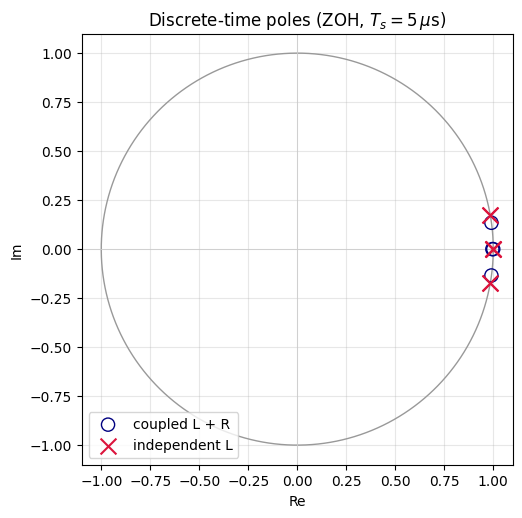

In [11]:
# Zero-order-hold discretisation at f_sw = 200 kHz (Appendix B.10).
# A~ is singular, so A_d = expm(A~ Ts) and B_d via the augmented-exponential trick.
Ad = sla.expm(A_indep * T_S)
n, m = A_indep.shape[0], Bd_indep.shape[1]
Maug = np.zeros((n+m, n+m))
Maug[:n, :n] = A_indep
Maug[:n, n:] = Bd_indep
Bd_d = sla.expm(Maug * T_S)[:n, n:]

evd = np.linalg.eigvals(Ad)
print('Discrete A_d eigenvalues:', np.array_str(evd, precision=4, suppress_small=True))
print('|lambda_d| =', np.array_str(np.abs(evd), precision=4))
print('All four discrete poles sit on the unit circle (mirror of marginal stability).')

# ---- z-plane plot ----
fig, ax = plt.subplots(figsize=(5.6, 5.6))
th = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(th), np.sin(th), '0.6', lw=1.0)
ax.scatter(evd.real, evd.imag, s=130, marker='x', color='crimson', zorder=3)
evd_c = np.linalg.eigvals(sla.expm(A_coup * T_S))
ax.scatter(evd_c.real, evd_c.imag, s=90, marker='o', facecolors='none',
           edgecolors='navy', zorder=3, label='coupled L + R')
ax.scatter(evd.real, evd.imag, s=130, marker='x', color='crimson', zorder=3,
           label='independent L')
ax.axhline(0, color='0.8', lw=0.6); ax.axvline(0, color='0.8', lw=0.6)
ax.set_aspect('equal'); ax.set_xlabel('Re'); ax.set_ylabel('Im')
ax.set_title('Discrete-time poles (ZOH, $T_s=5\\,\\mu$s)')
ax.legend(loc='lower left'); ax.grid(alpha=0.3)
plt.show()

## 11 · Phase portraits of the resonant core

The heart of the open-loop dynamics is a single $L$–$C$ resonator (at $D=0.5$, $\omega_0=1/\sqrt{LC}$).
Plotting the normalised state $(v,\;Z_0 i)$ with $Z_0=\sqrt{L/C}$ keeps both axes in volts so the ideal
orbits are circles. Three regimes:

* **(a)** ideal core — a marginal **center**, energy-conserving closed orbits;
* **(b)** physical winding resistance — a stable **focus**, but $\zeta\!\approx\!0.003$: practically still a
  center over the timescales of interest (this is *why* passive damping cannot be relied upon);
* **(c)** with the inner current loop active — the feedback emulates a series resistance and the
  trajectory spirals firmly into the operating point.

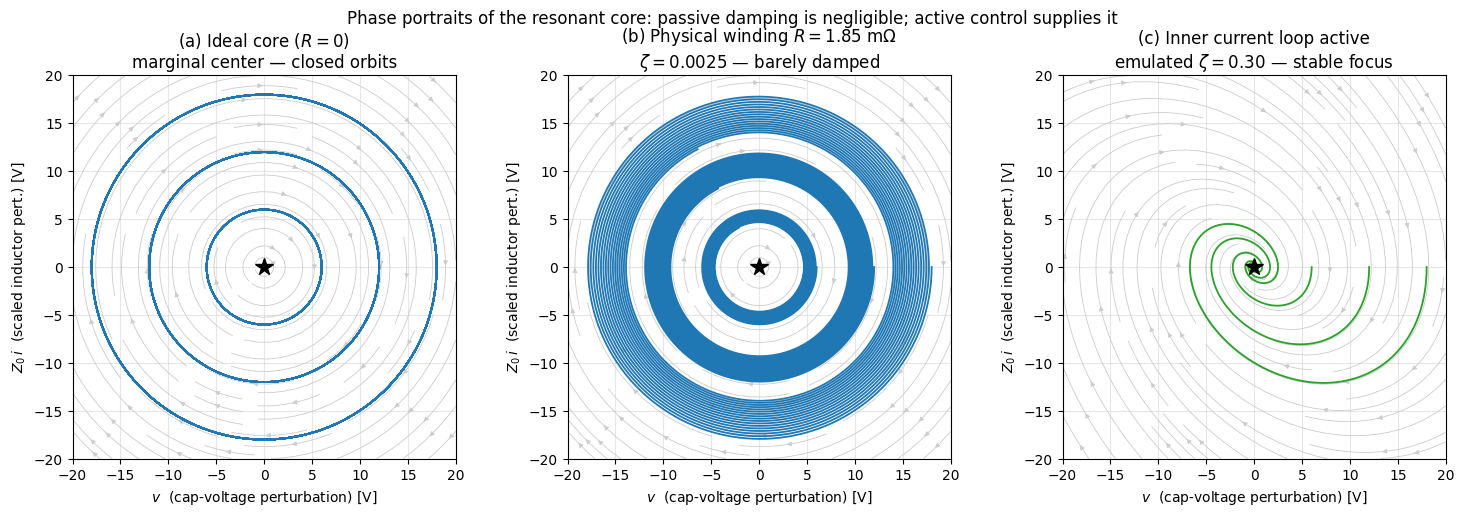

omega0 = 34922 rad/s ; Z0 = 0.286 ohm ; passive zeta = 0.0025


In [12]:
from scipy.integrate import solve_ivp

# Phase portraits of the resonant core (one L, one C). At D=0.5 the common-mode
# resonance is exactly omega0 = 1/sqrt(L C). Normalised state (v, p = Z0 i) keeps
# both axes in volts so the undamped orbits are circles:
#     dv/dt = w0 p ,   dp/dt = -w0 v - 2 zeta w0 p
w0_core = 1/np.sqrt(L_IND*C_CAP)
Z0      = np.sqrt(L_IND/C_CAP)
zeta_phys = (R_W/2)*np.sqrt(C_CAP/(L_SELF+L_M))   # passive damping (common-mode L)

def _field(zeta):
    return lambda t, z: [w0_core*z[1], -w0_core*z[0] - 2*zeta*w0_core*z[1]]

def portrait(ax, zeta, title, col='tab:blue'):
    V, P = np.meshgrid(np.linspace(-20, 20, 22), np.linspace(-20, 20, 22))
    dV, dP = w0_core*P, -w0_core*V - 2*zeta*w0_core*P
    nrm = np.hypot(dV, dP); nrm[nrm == 0] = 1
    ax.streamplot(V, P, dV/nrm, dP/nrm, color='0.8', density=1.0, linewidth=0.6, arrowsize=0.7)
    for v0 in (6, 12, 18):
        s = solve_ivp(_field(zeta), (0, 3e-3), [v0, 0.0],
                      t_eval=np.linspace(0, 3e-3, 8000), rtol=1e-9, atol=1e-12)
        ax.plot(s.y[0], s.y[1], color=col, lw=1.3)
    ax.plot(0, 0, 'k*', ms=13)
    ax.set_xlabel('$v$  (cap-voltage perturbation) [V]')
    ax.set_ylabel('$Z_0\\,i$  (scaled inductor pert.) [V]')
    ax.set_title(title); ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
portrait(ax[0], 0.0, '(a) Ideal core ($R=0$)\nmarginal center — closed orbits')
portrait(ax[1], zeta_phys,
         f'(b) Physical winding $R={R_W*1e3:.2f}$ m$\\Omega$\n$\\zeta={zeta_phys:.4f}$ — barely damped')
portrait(ax[2], 0.30,
         '(c) Inner current loop active\nemulated $\\zeta=0.30$ — stable focus', col='tab:green')
fig.suptitle('Phase portraits of the resonant core: passive damping is negligible; '
             'active control supplies it', fontsize=12)
fig.tight_layout()
plt.show()
print('omega0 = %.0f rad/s ; Z0 = %.3f ohm ; passive zeta = %.4f' % (w0_core, Z0, zeta_phys))

### Resonance vs duty cycle

$\omega_0(D)$ is minimised at $D=0.5$ and rises toward the duty limits; the coupled inductor (larger
common-mode $L_{cm}$) lowers it. This is the frequency the inner loop must stay an order of magnitude
above to treat the LC dynamics as quasi-static.

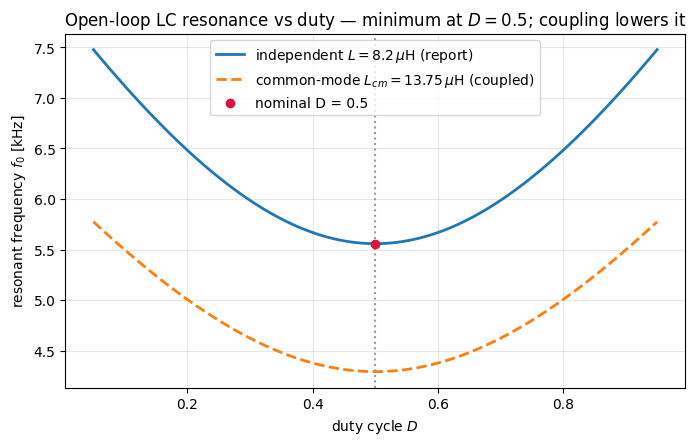

f0 at D=0.5: independent 5.56 kHz , coupled 4.29 kHz


In [13]:
# How the open-loop resonance moves with duty cycle and with the inductor model.
#   omega0^2 = 2 D^2/(L C1) + 2 (1-D)^2/(L C2)
Dgrid = np.linspace(0.05, 0.95, 200)
def w0_of_D(Leff):
    return np.sqrt(2*Dgrid**2/(Leff*C_CAP) + 2*(1-Dgrid)**2/(Leff*C_CAP))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(Dgrid, w0_of_D(L_IND)/(2*np.pi)/1e3, lw=2,
        label=f'independent $L={L_IND*1e6:.1f}\\,\\mu$H (report)')
ax.plot(Dgrid, w0_of_D(L_SELF+L_M)/(2*np.pi)/1e3, lw=2, ls='--',
        label=f'common-mode $L_{{cm}}={(L_SELF+L_M)*1e6:.2f}\\,\\mu$H (coupled)')
ax.axvline(0.5, color='0.6', ls=':')
ax.scatter([0.5], [w0_of_D(L_IND)[np.argmin(abs(Dgrid-0.5))]/(2*np.pi)/1e3],
           color='crimson', zorder=3, label='nominal D = 0.5')
ax.set_xlabel('duty cycle $D$'); ax.set_ylabel('resonant frequency $f_0$ [kHz]')
ax.set_title('Open-loop LC resonance vs duty — minimum at $D=0.5$; coupling lowers it')
ax.legend(); ax.grid(alpha=0.3)
plt.show()
print('f0 at D=0.5: independent %.2f kHz , coupled %.2f kHz'
      % (1/np.sqrt(L_IND*C_CAP)/(2*np.pi)/1e3, 1/np.sqrt((L_SELF+L_M)*C_CAP)/(2*np.pi)/1e3))

## 12 · Cascaded PI controller design

The modal split motivates the three-loop cascade with ~10× bandwidth separation (Table 4):

| Loop | Controlled quantity | Plant (simplified) | Target crossover |
|------|--------------------|--------------------|------------------|
| Inner (per phase) | $I_{L1},I_{L2}$ | integrator $V_\Sigma/(sL)$ | 10 kHz |
| Voltage | $V_{C1}$ | $2D/(sC_1)$ | 1 kHz |
| Balance | $I_{L1}-I_{L2}$ | integrator $V_\Sigma/(sL)$ | 5 kHz |
| MPPT (Sem 2) | $V_{C1}$ reference | — | ~10 Hz |

Each PI places its zero a decade below crossover, giving $\approx 84°$ phase margin (B.11):

$$K_{p,i}=\frac{\omega_{ci}L}{V_\Sigma},\;\;\tau_i=\frac{10}{\omega_{ci}};\qquad
K_{p,v}=\frac{\omega_{cv}C_1}{2D};\qquad K_{p,\delta}=\frac{\omega_{c\delta}L}{V_\Sigma}$$

The root loci confirm the textbook PI-on-an-integrator shape: a double pole at the origin and a real-axis
zero, with the closed-loop branches drawn into the left half-plane.

> **The inner-loop instability from the report (Fig. 8)** is *not* a tuning problem — a fixed current
> reference is not a valid target under mismatch (the controllable range of one substring depends on the
> other's irradiance). The cure is the voltage loop supplying an operating-point-aware reference, exactly
> the cascade designed here. This is the natural continuation point for Semester 2.

Designed PI gains:
  inner current  Kp_i = 0.00678 , tau_i = 159.2 us , Ki_i = 42.6
  voltage        Kp_v = 0.6283 , tau_v = 1591.5 us , Ki_v = 394.8
  balance        Kp_d = 0.00339 , tau_d = 318.3 us , Ki_d = 10.6


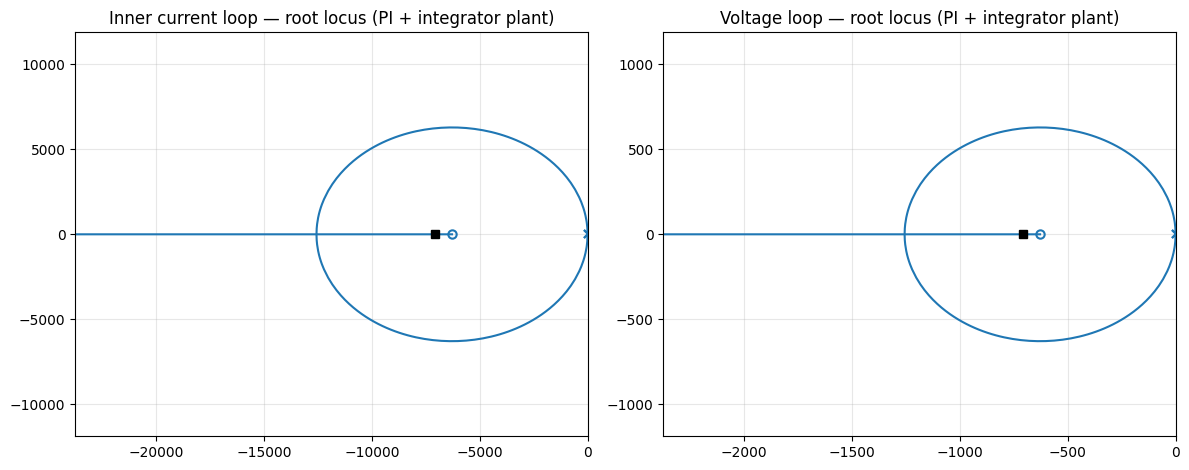

In [14]:
# Cascaded PI gain design (Appendix B.11, Table 4).  Each loop: PI zero placed
# one decade below crossover -> ~84 deg phase margin.
s = ct.tf('s')

def pi_loop(Kp, tau, plant):
    return plant * Kp*(tau*s + 1)/(tau*s)

# Inner phase-current loop:  plant = pure integrator V_Sigma/(sL)
wci   = 2*np.pi*10e3
tau_i = 10/wci
Kp_i  = wci*L_IND/VSIG
Li    = pi_loop(Kp_i, tau_i, VSIG/(s*L_IND))

# Voltage loop (closed inner loop ~ ideal): plant = 2D/(sC1)
wcv   = 2*np.pi*1e3
tau_v = 10/wcv
Kp_v  = wcv*C_CAP/(2*D_OP)
Lv    = pi_loop(Kp_v, tau_v, (2*D_OP)/(s*C_CAP))

# Balance loop on I_diff (same structure as the current loop)
wcd   = 2*np.pi*5e3
tau_d = 10/wcd
Kp_d  = wcd*L_IND/VSIG
Ld    = pi_loop(Kp_d, tau_d, VSIG/(s*L_IND))

print('Designed PI gains:')
print('  inner current  Kp_i = %.5f , tau_i = %.1f us , Ki_i = %.1f' % (Kp_i, tau_i*1e6, Kp_i/tau_i))
print('  voltage        Kp_v = %.4f , tau_v = %.1f us , Ki_v = %.1f' % (Kp_v, tau_v*1e6, Kp_v/tau_v))
print('  balance        Kp_d = %.5f , tau_d = %.1f us , Ki_d = %.1f' % (Kp_d, tau_d*1e6, Kp_d/tau_d))

# ---- Root loci of the two key loops ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for axi, Lsys, ttl in ((ax[0], Li, 'Inner current loop'), (ax[1], Lv, 'Voltage loop')):
    ct.root_locus(Lsys, ax=axi, initial_gain=1.0)
    axi.set_title(ttl + ' — root locus (PI + integrator plant)')
    axi.grid(alpha=0.3)
fig.tight_layout()
plt.show()

inner current (10 kHz) crossover 10049 Hz , phase margin 84.3 deg
voltage (1 kHz)        crossover 1005 Hz , phase margin 84.3 deg
balance (5 kHz)        crossover 5025 Hz , phase margin 84.3 deg


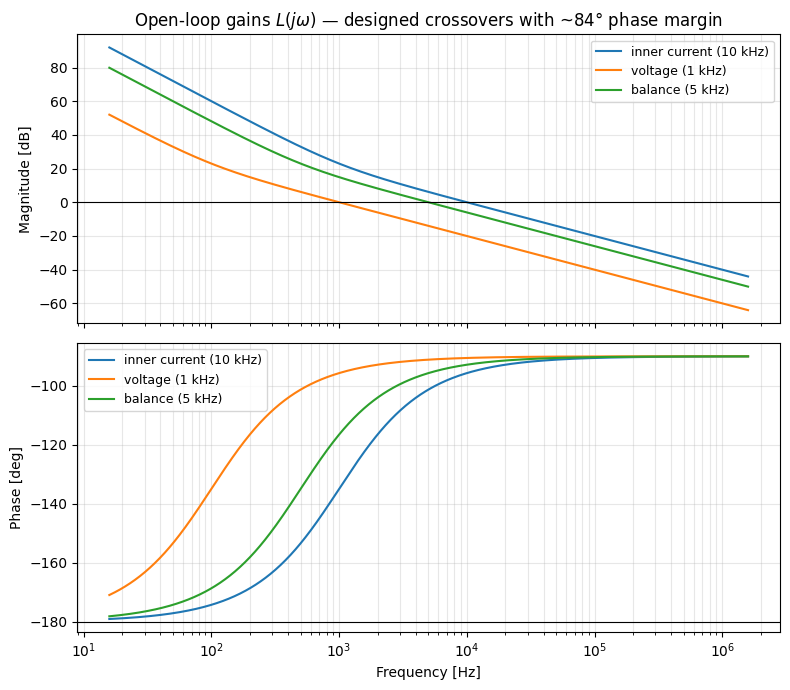

In [15]:
# Loop-gain Bode plots and stability margins for the three loops.
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
w = np.logspace(2, 7, 900)
for Lsys, lbl, col in ((Li, 'inner current (10 kHz)', 'tab:blue'),
                       (Lv, 'voltage (1 kHz)', 'tab:orange'),
                       (Ld, 'balance (5 kHz)', 'tab:green')):
    mag, ph, _ = ct.frequency_response(Lsys, w)
    ax[0].semilogx(w/(2*np.pi), 20*np.log10(mag), color=col, label=lbl)
    ax[1].semilogx(w/(2*np.pi), np.degrees(ph), color=col, label=lbl)
    gm, pm, wcg, wcp = ct.margin(Lsys)
    print('%-22s crossover %.0f Hz , phase margin %.1f deg' % (lbl, wcp/(2*np.pi), pm))
ax[0].axhline(0, color='k', lw=0.8); ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3, which='both')
ax[0].set_title('Open-loop gains $L(j\\omega)$ — designed crossovers with ~84$\\degree$ phase margin')
ax[1].axhline(-180, color='k', lw=0.8); ax[1].set_ylabel('Phase [deg]'); ax[1].set_xlabel('Frequency [Hz]')
ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3, which='both')
fig.tight_layout()
plt.show()

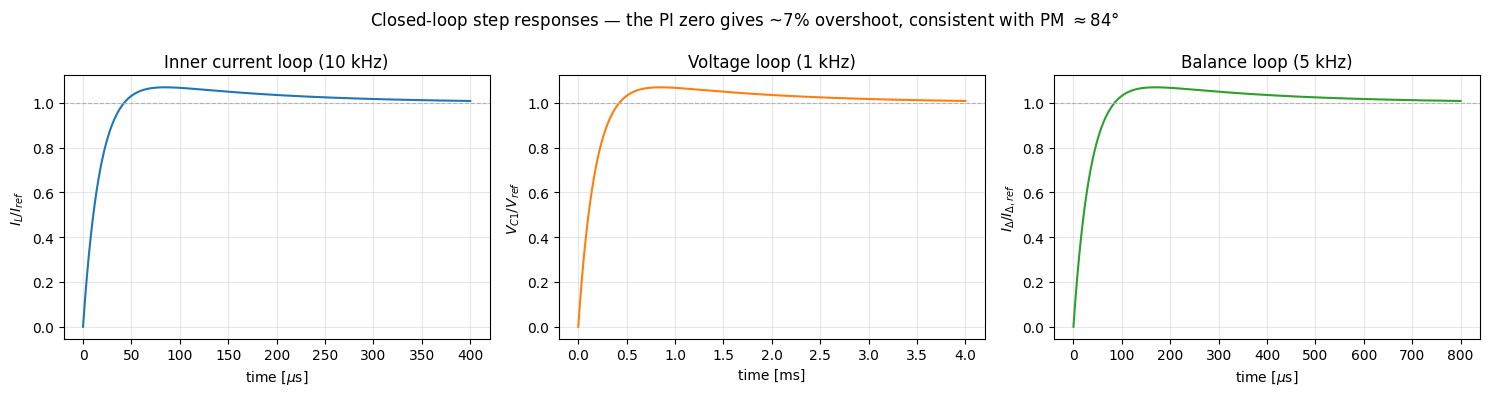

In [16]:
# Closed-loop reference-step responses (complementary sensitivity T = L/(1+L)).
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

Ti = ct.feedback(Li, 1)
t1, y1 = ct.step_response(Ti, T=np.linspace(0, 4e-4, 800))
ax[0].plot(t1*1e6, y1, color='tab:blue'); ax[0].axhline(1, color='0.7', ls='--', lw=0.8)
ax[0].set_title('Inner current loop (10 kHz)'); ax[0].set_xlabel('time [$\\mu$s]')
ax[0].set_ylabel('$I_L / I_{ref}$'); ax[0].grid(alpha=0.3)

Tv = ct.feedback(Lv, 1)
t2, y2 = ct.step_response(Tv, T=np.linspace(0, 4e-3, 800))
ax[1].plot(t2*1e3, y2, color='tab:orange'); ax[1].axhline(1, color='0.7', ls='--', lw=0.8)
ax[1].set_title('Voltage loop (1 kHz)'); ax[1].set_xlabel('time [ms]')
ax[1].set_ylabel('$V_{C1} / V_{ref}$'); ax[1].grid(alpha=0.3)

Td = ct.feedback(Ld, 1)
t3, y3 = ct.step_response(Td, T=np.linspace(0, 8e-4, 800))
ax[2].plot(t3*1e6, y3, color='tab:green'); ax[2].axhline(1, color='0.7', ls='--', lw=0.8)
ax[2].set_title('Balance loop (5 kHz)'); ax[2].set_xlabel('time [$\\mu$s]')
ax[2].set_ylabel('$I_\\Delta / I_{\\Delta,ref}$'); ax[2].grid(alpha=0.3)

fig.suptitle('Closed-loop step responses — the PI zero gives ~7% overshoot, '
             'consistent with PM $\\approx 84\\degree$', fontsize=12)
fig.tight_layout()
plt.show()

## 13 · Summary of key analytical results

| Result | Expression | Eq. |
|--------|------------|-----|
| Steady-state duty relation | $D_A=D_B\equiv D$ | (B.6) |
| Equilibrium voltage ratio | $\bar V_{C2}/\bar V_{C1}=D/(1-D)$ | (B.7) |
| Steady duty (with load) | $D=(I_{load}-I_{pv1})/(I_{load}-I_{pv1}+I_{pv2})$ | (B.8) |
| Per-phase steady current | $\bar I=I_{pv2}/[2(1-D)]$ | (B.9) |
| Open-loop eigenvalues | $\{0,0,\pm j\omega_0\}$ | (B.10) |
| Natural resonance | $\omega_0^2=2D^2/(LC_1)+2(1-D)^2/(LC_2)$ | — |
| Controllability | full at all non-degenerate points | (B.8) |
| Observability ($V_C$ only) | rank 3 — differential current hidden | (B.9) |
| Observability ($V_C+I_{L1}$) | rank 4 — full state | (B.9) |

**What this notebook adds beyond the report.** The coupled-inductor (ERUC23-421K) T-model is carried
alongside the single-$L$ model and shown to move the marginal poles into the LHP; the modal decomposition,
phase portraits, root loci and Bode/step plots make the marginal-stability $\to$ actively-damped story
visual and quantitative.

**Next steps.** (i) Close the cascade in this averaged model and confirm the Fig. 8 failure mode
disappears once the voltage loop sets the current reference; (ii) add the **balance loop** on $I_\Delta$
(the 180°-interleaved phase-current equaliser); (iii) port the discrete PI prescriptions here as seed gains
into the QSPICE / Simulink switching models, where dead-time, ripple and the full coupled-inductor
behaviour are captured. The averaged model is the analytical scaffold; the switching simulators are the
high-fidelity refinement.